# Module: Single-Layer Perceptron with ReLU Activation -- Foundations, Optimization & Detailed Gradient Derivations

- **Linear Algebra Fundamentals**: Geometric visualization of vectors in 2D space, vector addition mechanics, and matrix-vector linear transformations.
- **Dataset Splitting Refresher (Train / Validation / Test)**: Structuring clean 3-way dataset partitions on a slightly non-linear continuous signal with realistic noise.
- **Single-Layer Perceptron with ReLU Architecture**: Visual single-neuron architecture diagram (inputs, weight, bias, linear combination, **ReLU** activation unit, and output prediction).
- **In-Depth Calculus & Gradient Derivations with ReLU**:
  - The forward prediction function: $\hat{y} = \text{ReLU}(wx + b)$.
  - The Mean Squared Error (MSE) loss model.
  - Combining the two equations by directly substituting $\hat{y}$.
  - The **Chain Rule** with the ReLU activation derivative: $\frac{\partial \mathcal{L}}{\partial w} = \frac{\partial \mathcal{L}}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial z} \cdot \frac{\partial z}{\partial w}$.
  - Scalar and vectorized matrix gradient formulations.
  - Numerical walkthrough demonstrating active vs. inactive ReLU gating.
- **Implementation & Gradient Descent from Scratch**: Training the single-layer ReLU perceptron regressor in pure NumPy, evaluating convergence, and visualizing the fitted piece-wise curve.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

### 1. Linear Algebra Building Blocks: What is a Vector?

- **Vector Definition**: A vector is an ordered list of numbers representing both **magnitude** (length) and **direction** in coordinate space.
- In machine learning, a single data observation with $p$ features is represented as a feature vector:
  $$\vec{x} = \begin{bmatrix} x_1 \\ x_2 \\ \vdots \\ x_p \end{bmatrix} \in \mathbb{R}^p$$
- **Geometric Intuition (2D Space)**:
  - If we have two features ($x_1, x_2$), the vector can be visualized as an arrow pointing from the origin $(0, 0)$ to the point $(x_1, x_2)$.
  - **Vector Addition**: Combining two vectors tip-to-tail (parallelogram rule):
    $$\vec{u} + \vec{v} = \begin{bmatrix} u_1 + v_1 \\ u_2 + v_2 \end{bmatrix}$$
  - **Scalar Scaling**: Multiplying by a constant $c$ changes length (and reverses direction if $c < 0$):
    $$c \cdot \vec{u} = \begin{bmatrix} c u_1 \\ c u_2 \end{bmatrix}$$
- Below, we plot two simple vectors $\vec{v}_1 = [3, 2]^T$ and $\vec{v}_2 = [-1, 3]^T$, along with their resultant sum $\vec{v}_3 = \vec{v}_1 + \vec{v}_2 = [2, 5]^T$ in 2D space.

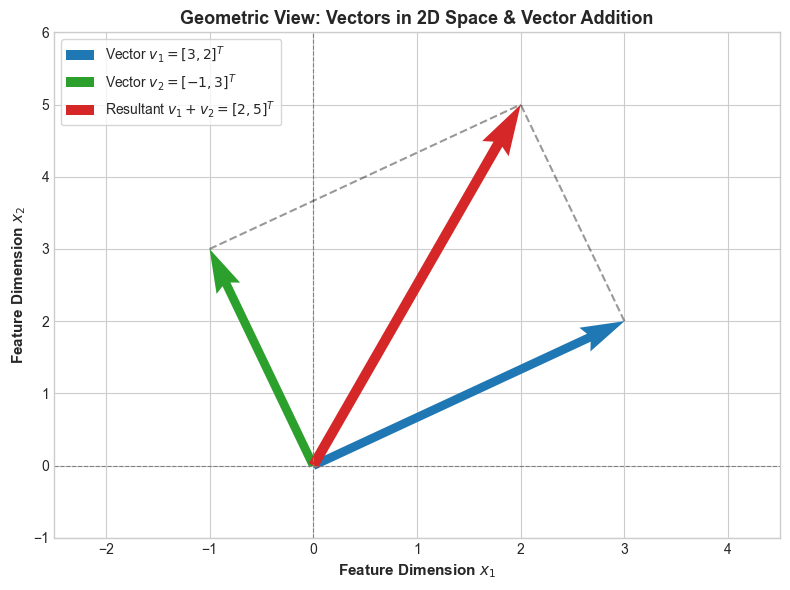

In [2]:
v1 = np.array([3.0, 2.0])
v2 = np.array([-1.0, 3.0])
v_sum = v1 + v2

fig, ax = plt.subplots(figsize=(8, 6))

ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)

origin = [0, 0]
ax.quiver(*origin, *v1, angles='xy', scale_units='xy', scale=1, color='#1f77b4', width=0.012, label=r'Vector $v_1 = [3, 2]^T$')
ax.quiver(*origin, *v2, angles='xy', scale_units='xy', scale=1, color='#2ca02c', width=0.012, label=r'Vector $v_2 = [-1, 3]^T$')
ax.quiver(*origin, *v_sum, angles='xy', scale_units='xy', scale=1, color='#d62728', width=0.014, label=r'Resultant $v_1 + v_2 = [2, 5]^T$')

ax.plot([v1[0], v_sum[0]], [v1[1], v_sum[1]], 'k--', alpha=0.4)
ax.plot([v2[0], v_sum[0]], [v2[1], v_sum[1]], 'k--', alpha=0.4)

ax.set_xlim(-2.5, 4.5)
ax.set_ylim(-1.0, 6.0)
ax.set_xlabel('Feature Dimension $x_1$', fontsize=11, fontweight='bold')
ax.set_ylabel('Feature Dimension $x_2$', fontsize=11, fontweight='bold')
ax.set_title('Geometric View: Vectors in 2D Space & Vector Addition', fontsize=13, fontweight='bold')
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

### 2. Linear Algebra Building Blocks: What is a Matrix?

- **Matrix Definition**: A matrix is a 2D rectangular array of numbers organized into rows and columns:
  $$W = \begin{bmatrix} w_{11} & w_{12} & \dots & w_{1n} \\ w_{21} & w_{22} & \dots & w_{2n} \\ \vdots & \vdots & \ddots & \vdots \\ w_{m1} & w_{m2} & \dots & w_{mn} \end{bmatrix} \in \mathbb{R}^{m \times n}$$
- **Role in Perceptrons**:
  - A matrix acts as a **linear transformation operator**.
  - When an input feature vector $\vec{x} \in \mathbb{R}^n$ enters a perceptron layer, the layer multiplies $\vec{x}$ by a weight matrix $W \in \mathbb{R}^{m \times n}$ and adds a bias vector $\vec{b} \in \mathbb{R}^m$:
    $$\vec{z} = W \vec{x} + \vec{b}$$
  - **Dimension Check**:
    $$\underbrace{W}_{(m \times n)} \times \underbrace{\vec{x}}_{(n \times 1)} + \underbrace{\vec{b}}_{(m \times 1)} = \underbrace{\vec{z}}_{(m \times 1)}$$
  - In a single-layer perceptron regressor with 1 input and 1 output, $W$ is a scalar weight $w \in \mathbb{R}^1$.
- Below, we demonstrate matrix-vector operations with `# important` tags on key mathematical lines.

In [3]:
# important
x = np.array([1.5, -2.0])

# important
W = np.array([
    [ 0.8, -0.5],
    [ 1.2,  0.4],
    [-0.3,  0.9]
])

# important
b = np.array([0.1, -0.2, 0.5])

# important
z = np.dot(W, x) + b

print("--- Single Sample Forward Pass ---")
print(f"Input Vector x (shape {x.shape}):\n  {x}")
print(f"Weight Matrix W (shape {W.shape}):\n{W}")
print(f"Bias Vector b (shape {b.shape}):\n  {b}")
print(f"Linear Output z = Wx + b (shape {z.shape}):\n  {z}\n")

# important
X_batch = np.array([
    [ 1.5, -2.0],
    [ 0.5,  1.0],
    [-1.0, -0.5],
    [ 2.0,  0.0]
])

# important
Z_batch = np.dot(X_batch, W.T) + b

print("--- Batch Processing (4 samples at once) ---")
print(f"Input Batch X (shape {X_batch.shape}):\n{X_batch}")
print(f"Batch Output Z = X @ W.T + b (shape {Z_batch.shape}):\n{Z_batch}")

--- Single Sample Forward Pass ---
Input Vector x (shape (2,)):
  [ 1.5 -2. ]
Weight Matrix W (shape (3, 2)):
[[ 0.8 -0.5]
 [ 1.2  0.4]
 [-0.3  0.9]]
Bias Vector b (shape (3,)):
  [ 0.1 -0.2  0.5]
Linear Output z = Wx + b (shape (3,)):
  [ 2.3   0.8  -1.75]

--- Batch Processing (4 samples at once) ---
Input Batch X (shape (4, 2)):
[[ 1.5 -2. ]
 [ 0.5  1. ]
 [-1.  -0.5]
 [ 2.   0. ]]
Batch Output Z = X @ W.T + b (shape (4, 3)):
[[ 2.30000000e+00  8.00000000e-01 -1.75000000e+00]
 [ 2.77555756e-17  8.00000000e-01  1.25000000e+00]
 [-4.50000000e-01 -1.60000000e+00  3.50000000e-01]
 [ 1.70000000e+00  2.20000000e+00 -1.00000000e-01]]


### 3. Machine Learning Refresher: Train, Validation, and Test Splits for a Slightly Non-Linear Dataset

Why do we never evaluate or select regression models on the data used to train them?

- **The Danger of In-Sample Evaluation**:
  - A model can achieve near-zero training error simply by memorizing high-frequency noise (overfitting).
  - Low training error does **not** guarantee accurate predictions on new, unseen test observations.

- **The Three-Way Split**:
  1. **Training Set (~60%)**: Used directly by gradient descent to optimize model weight $w$ and bias $b$.
  2. **Validation Set (~20%)**: Held-out during training. Used to tune hyperparameters (learning rate $\eta$, number of epochs) and detect overfitting.
  3. **Test Set (~20%)**: Kept in an "unseen vault" until all modeling decisions are finalized. Provides the final unbiased audit of generalization performance.

- **The Slightly Non-Linear Dataset**:
  We generate synthetic observations featuring both a threshold at zero and gentle non-linear upward curvature:
  $$y = \max(0, 2.2x + 1.5) + 0.08x^2 + \epsilon, \qquad x \in [-4, 4]$$
  where $\epsilon \sim \mathcal{N}(0, 0.35)$ is realistic noise.

In [4]:
np.random.seed(42)
n_samples = 300

# important
X_all = np.sort(np.random.uniform(-4, 4, n_samples)).reshape(-1, 1)
# important
noise = np.random.normal(0, 0.35, (n_samples, 1))
# important
y_all = np.maximum(0, 2.2 * X_all + 1.5) + 0.08 * (X_all ** 2) + noise

# important
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42
)

# important
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42
)

print(f"Total Dataset Size:      {len(X_all)} samples")
print(f"  -> Training Set:       {len(X_train)} samples ({len(X_train)/len(X_all):.0%})")
print(f"  -> Validation Set:     {len(X_val)} samples ({len(X_val)/len(X_all):.0%})")
print(f"  -> Test Set (Held-out): {len(X_test)} samples ({len(X_test)/len(X_all):.0%})")

Total Dataset Size:      300 samples
  -> Training Set:       180 samples (60%)
  -> Validation Set:     60 samples (20%)
  -> Test Set (Held-out): 60 samples (20%)


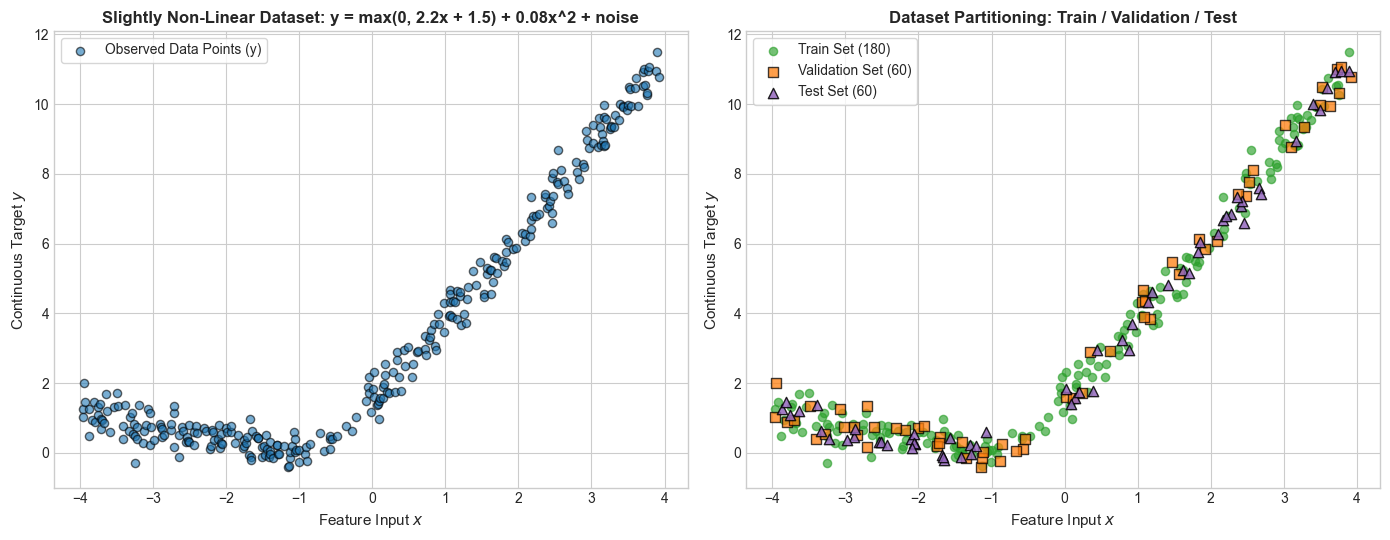

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(X_all, y_all, color='#1f77b4', alpha=0.6, edgecolors='k', s=35, label='Observed Data Points (y)')
axes[0].set_title('Slightly Non-Linear Dataset: y = max(0, 2.2x + 1.5) + 0.08x^2 + noise', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Feature Input $x$', fontsize=11)
axes[0].set_ylabel('Continuous Target $y$', fontsize=11)
axes[0].legend(frameon=True, loc='upper left')

axes[1].scatter(X_train, y_train, color='#2ca02c', alpha=0.65, marker='o', s=35, label=f'Train Set ({len(X_train)})')
axes[1].scatter(X_val, y_val, color='#ff7f0e', alpha=0.75, marker='s', s=45, edgecolors='k', label=f'Validation Set ({len(X_val)})')
axes[1].scatter(X_test, y_test, color='#9467bd', alpha=0.85, marker='^', s=55, edgecolors='k', label=f'Test Set ({len(X_test)})')
axes[1].set_title('Dataset Partitioning: Train / Validation / Test', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Feature Input $x$', fontsize=11)
axes[1].set_ylabel('Continuous Target $y$', fontsize=11)
axes[1].legend(frameon=True, loc='upper left')

plt.tight_layout()
plt.show()

### 4. Single-Layer Perceptron Architecture with ReLU Activation

- **Architecture Details**:
  - **Input**: A single feature $x$.
  - **Linear Combination (Pre-activation)**:
    $$z = w x + b$$
  - **Activation Unit (ReLU)**:
    $$\hat{y} = \text{ReLU}(z) = \max(0, w x + b)$$
  - **Why ReLU?**:
    - For $z \le 0$, $\hat{y} = 0$ (the perceptron is flat / inactive).
    - For $z > 0$, $\hat{y} = wx + b$ (the perceptron acts as an active linear ramp).
    - This allows a single neuron to model threshold and hinge behaviors that pure linear regression cannot capture!
- Below is the architecture diagram of the single-layer perceptron with the ReLU activation function.

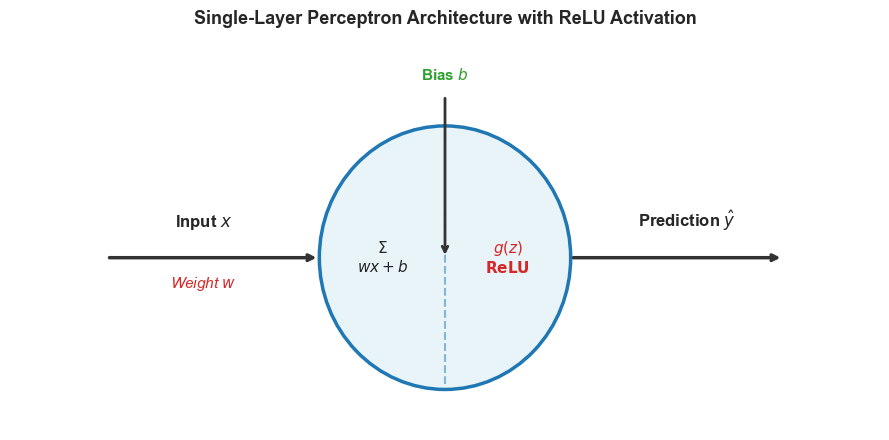

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))

c = patches.Circle((5.0, 2.5), 1.3, facecolor='#e8f4f8', edgecolor='#1f77b4', linewidth=2.5)
ax.add_patch(c)

ax.annotate('', xy=(3.7, 2.5), xytext=(1.5, 2.5),
            arrowprops=dict(arrowstyle='->', lw=2.5, color='#333333'))
ax.text(2.5, 2.8, r'Input $x$', fontsize=12, fontweight='bold', ha='center')
ax.text(2.5, 2.2, r'Weight $w$', fontsize=11, color='#d62728', style='italic', ha='center')

ax.annotate('', xy=(5.0, 2.5), xytext=(5.0, 4.1),
            arrowprops=dict(arrowstyle='->', lw=2.0, color='#333333'))
ax.text(5.0, 4.25, r'Bias $b$', fontsize=11, fontweight='bold', ha='center', color='#2ca02c')

ax.annotate('', xy=(8.5, 2.5), xytext=(6.3, 2.5),
            arrowprops=dict(arrowstyle='->', lw=2.5, color='#333333'))
ax.text(7.5, 2.8, r'Prediction $\hat{y}$', fontsize=12, fontweight='bold', ha='center')

ax.plot([5.0, 5.0], [1.25, 3.75], color='#1f77b4', linestyle='--', alpha=0.5, lw=1.5)

ax.text(4.35, 2.5, '$\Sigma$\n$wx + b$', fontsize=11, fontweight='bold', ha='center', va='center')
ax.text(5.65, 2.5, '$g(z)$\n$\mathbf{ReLU}$', fontsize=11, fontweight='bold', ha='center', va='center', color='#d62728')

ax.set_xlim(0.5, 9.5)
ax.set_ylim(0.8, 4.6)
ax.axis('off')
ax.set_title('Single-Layer Perceptron Architecture with ReLU Activation', fontsize=13, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

### 5. Detailed Mathematical Derivations of the Gradient with ReLU

To train the perceptron using gradient descent, we must compute **how changing weight $w$ and bias $b$ alters the loss**.

---

#### A. Combining the Loss Model & Perceptron Prediction
Rather than defining the loss in terms of $w$ and $b$ right away, we start simply with the **Loss Model written in terms of $\hat{y}$**:
$$\mathcal{L} = \frac{1}{2N} \sum_{i=1}^N \left( \hat{y}_i - y_i \right)^2$$

Here, $\hat{y}_i$ is the single-layer perceptron's prediction using the **ReLU** activation:
$$\hat{y}_i = \text{ReLU}(z_i) = \max(0, z_i), \qquad \text{where } z_i = w x_i + b$$

Now, we **combine the two equations by plugging $\hat{y}_i$ directly into the loss model**:
$$\mathcal{L} = \frac{1}{2N} \sum_{i=1}^N \left( \underbrace{\text{ReLU}(w x_i + b)}_{\hat{y}_i} - y_i \right)^2$$

*(Note: The factor of $\frac{1}{2}$ cancels out with the exponent $2$ during differentiation).*

---

#### B. Our Core Optimization Goal
Our goal is to compute the partial derivatives of the loss model with respect to each parameter:
$$\frac{\partial \mathcal{L}}{\partial w} \quad \text{and} \quad \frac{\partial \mathcal{L}}{\partial b}$$
These gradients indicate the direction of steepest ascent. Gradient descent updates parameters in the opposite direction:
$$w \leftarrow w - \eta \frac{\partial \mathcal{L}}{\partial w}, \qquad b \leftarrow b - \eta \frac{\partial \mathcal{L}}{\partial b}$$
where $\eta > 0$ is the learning rate.

---

#### C. The Chain Rule with ReLU
Notice the nested dependency chain:
$$w, b \xrightarrow{\text{linear combo}} z_i \xrightarrow{\text{ReLU}} \hat{y}_i \xrightarrow{\text{MSE}} \mathcal{L}$$
Because $w$ affects the loss through both the pre-activation $z_i$ and the ReLU activation $\hat{y}_i$, the **Chain Rule** decomposes the derivative into three modular factors:
$$\frac{\partial \mathcal{L}}{\partial w} = \frac{\partial \mathcal{L}}{\partial \hat{y}_i} \cdot \frac{\partial \hat{y}_i}{\partial z_i} \cdot \frac{\partial z_i}{\partial w}$$

---

#### D. Step-by-Step Gradient Derivation

- **Step 1: Derivative of Loss w.r.t. Prediction ($\frac{\partial \mathcal{L}}{\partial \hat{y}_i}$)**:
  Applying the power rule to the squared loss:
  $$\frac{\partial \mathcal{L}}{\partial \hat{y}_i} = \frac{\partial}{\partial \hat{y}_i} \left[ \frac{1}{2N} \sum_{j=1}^N (\hat{y}_j - y_j)^2 \right] = \frac{1}{N} (\hat{y}_i - y_i)$$
  This term represents the **residual error** (prediction minus ground truth).

- **Step 2: Derivative of ReLU Activation w.r.t. Pre-activation ($\frac{\partial \hat{y}_i}{\partial z_i}$)**:
  Since $\hat{y}_i = \text{ReLU}(z_i) = \max(0, z_i)$, its derivative is a step function:
  $$\frac{\partial \hat{y}_i}{\partial z_i} = \frac{d}{dz_i} \text{ReLU}(z_i) = \begin{cases} 1 & \text{if } z_i > 0 \\ 0 & \text{if } z_i \le 0 \end{cases} \equiv \mathbb{I}(z_i > 0)$$
  **Crucial Insight**:
  - When $z_i > 0$, the ReLU gate is **open** ($1$), allowing the error signal to pass through unhindered.
  - When $z_i \le 0$, the ReLU gate is **closed** ($0$), blocking the gradient completely!

- **Step 3: Derivative of Pre-activation w.r.t. Weight $w$ ($\frac{\partial z_i}{\partial w}$)**:
  Since $z_i = w x_i + b$:
  $$\frac{\partial z_i}{\partial w} = \frac{\partial}{\partial w} (w x_i + b) = x_i$$

- **Step 4: Combining to Find $\frac{\partial \mathcal{L}}{\partial w}$**:
  Multiplying Steps 1, 2, and 3 via the chain rule and summing across all $N$ samples:
  $$\frac{\partial \mathcal{L}}{\partial w} = \frac{1}{N} \sum_{i=1}^N (\hat{y}_i - y_i) \cdot \mathbb{I}(z_i > 0) \cdot x_i$$
  **Key Takeaway**: Only observations where $z_i > 0$ contribute to the weight gradient!

- **Step 5: Derivative of Pre-activation w.r.t. Bias $b$ ($\frac{\partial z_i}{\partial b}$)**:
  Since $z_i = w x_i + b$:
  $$\frac{\partial z_i}{\partial b} = 1$$
  Multiplying via the chain rule gives the bias gradient:
  $$\frac{\partial \mathcal{L}}{\partial b} = \frac{1}{N} \sum_{i=1}^N (\hat{y}_i - y_i) \cdot \mathbb{I}(z_i > 0) \cdot 1 = \frac{1}{N} \sum_{i=1}^N (\hat{y}_i - y_i) \cdot \mathbb{I}(z_i > 0)$$

---

#### E. Vectorized Matrix Formulation
In NumPy, we vectorize over the entire dataset:
$$Z = X w + b$$
$$\hat{Y} = \text{ReLU}(Z)$$
$$dZ = (\hat{Y} - Y) \odot \mathbb{I}(Z > 0)$$
$$\nabla_w \mathcal{L} = \frac{1}{N} X^T dZ$$
$$\nabla_b \mathcal{L} = \frac{1}{N} \sum dZ$$

---

#### F. Concrete Numerical Walkthrough Example
Let us trace an explicit manual calculation for two contrasting observations:
- **Parameters**: $w = 2.0, \quad b = 1.0, \quad \eta = 0.1$

1. **Case A (Active Region, $z > 0$)**:
   - $x = 1.5, \quad y = 5.0$
   - $z = (2.0)(1.5) + 1.0 = 4.0 > 0$
   - $\hat{y} = \text{ReLU}(4.0) = 4.0$
   - $\text{Error: } (\hat{y} - y) = 4.0 - 5.0 = -1.0$
   - $\text{ReLU Derivative: } \mathbb{I}(z > 0) = 1$
   - $\frac{\partial \mathcal{L}}{\partial w} = (-1.0) \cdot (1) \cdot (1.5) = -1.5$ (Non-zero gradient updates $w$!)

2. **Case B (Inactive Region, $z \le 0$)**:
   - $x = -2.0, \quad y = 0.0$
   - $z = (2.0)(-2.0) + 1.0 = -3.0 \le 0$
   - $\hat{y} = \text{ReLU}(-3.0) = 0.0$
   - $\text{Error: } (\hat{y} - y) = 0.0 - 0.0 = 0.0$
   - $\text{ReLU Derivative: } \mathbb{I}(z > 0) = 0$
   - $\frac{\partial \mathcal{L}}{\partial w} = (0.0) \cdot (0) \cdot (-2.0) = 0.0$ (Zero gradient: gate is closed!).

In [7]:
# important
w_init = 2.0
b_init = 1.0
lr_demo = 0.1

# case a: active neuron (z > 0)
x_active = 1.5
y_active = 5.0

# important
z_active = w_init * x_active + b_init
# important
y_hat_active = max(0.0, z_active)
# important
error_active = y_hat_active - y_active
# important
relu_grad_active = 1.0 if z_active > 0 else 0.0

# important
grad_w_active = error_active * relu_grad_active * x_active
# important
grad_b_active = error_active * relu_grad_active

# case b: inactive neuron (z <= 0)
x_inactive = -2.0
y_inactive = 0.0

# important
z_inactive = w_init * x_inactive + b_init
# important
y_hat_inactive = max(0.0, z_inactive)
# important
error_inactive = y_hat_inactive - y_inactive
# important
relu_grad_inactive = 1.0 if z_inactive > 0 else 0.0

# important
grad_w_inactive = error_inactive * relu_grad_inactive * x_inactive

print("--- Concrete Numerical Gradient Walkthrough with ReLU ---")
print(f"Case A (Active, z > 0):")
print(f"  Input x = {x_active}, True y = {y_active}")
print(f"  z = {z_active:.2f} -> y_hat = ReLU({z_active:.2f}) = {y_hat_active:.2f}")
print(f"  Error (y_hat - y) = {error_active:.2f}")
print(f"  ReLU Gradient = {relu_grad_active:.2f} (Gate is OPEN)")
print(f"  dL/dw = error * relu_grad * x = ({error_active:.2f}) * ({relu_grad_active}) * ({x_active}) = {grad_w_active:.2f}")

print(f"\nCase B (Inactive, z <= 0):")
print(f"  Input x = {x_inactive}, True y = {y_inactive}")
print(f"  z = {z_inactive:.2f} -> y_hat = ReLU({z_inactive:.2f}) = {y_hat_inactive:.2f}")
print(f"  ReLU Gradient = {relu_grad_inactive:.2f} (Gate is CLOSED)")
print(f"  dL/dw = {grad_w_inactive:.2f} (Zero gradient: no parameter update from this sample!)")

--- Concrete Numerical Gradient Walkthrough with ReLU ---
Case A (Active, z > 0):
  Input x = 1.5, True y = 5.0
  z = 4.00 -> y_hat = ReLU(4.00) = 4.00
  Error (y_hat - y) = -1.00
  ReLU Gradient = 1.00 (Gate is OPEN)
  dL/dw = error * relu_grad * x = (-1.00) * (1.0) * (1.5) = -1.50

Case B (Inactive, z <= 0):
  Input x = -2.0, True y = 0.0
  z = -3.00 -> y_hat = ReLU(-3.00) = 0.00
  ReLU Gradient = 0.00 (Gate is CLOSED)
  dL/dw = -0.00 (Zero gradient: no parameter update from this sample!)


### 6. Fitting the Single-Layer Perceptron with ReLU from Scratch

We now implement the complete `SingleLayerReLUPerceptronRegressor` class using our derived gradients:
- **Forward Pass**: $Z = X w + b, \quad \hat{Y} = \text{ReLU}(Z)$.
- **Gradients**:
  $$\frac{\partial \mathcal{L}}{\partial w} = \frac{2}{N} \sum (\hat{y} - y) \cdot \mathbb{I}(z > 0) \cdot x$$
  $$\frac{\partial \mathcal{L}}{\partial b} = \frac{2}{N} \sum (\hat{y} - y) \cdot \mathbb{I}(z > 0)$$
- **Updates**:
  $$w \leftarrow w - \eta \cdot \frac{\partial \mathcal{L}}{\partial w}, \qquad b \leftarrow b - \eta \cdot \frac{\partial \mathcal{L}}{\partial b}$$

Below is the vectorized NumPy implementation with `# important` flags and all lowercase comments.

In [8]:
# important
# single layer perceptron regressor with relu activation
class SingleLayerReLUPerceptronRegressor:
    def __init__(self, lr=0.01):
        self.lr = lr
        # important
        # initialize weight and bias
        self.w = 0.5
        self.b = 0.5
        self.history = {'train_loss': [], 'val_loss': []}

    # important
    # relu activation function
    def relu(self, z):
        return np.maximum(0, z)

    # important
    # relu gradient for backpropagation
    def relu_derivative(self, z):
        return (z > 0).astype(float)

    # important
    # forward pass: z = w*x + b, y_hat = relu(z)
    def forward(self, X):
        z = X * self.w + self.b
        y_hat = self.relu(z)
        return y_hat, z

    # important
    # mean squared error loss function
    def compute_loss(self, y_true, y_pred):
        return np.mean((y_pred - y_true) ** 2)

    # important
    # gradient descent training loop
    def fit(self, X_tr, y_tr, X_v, y_v, epochs=800):
        N = len(X_tr)
        
        for epoch in range(1, epochs + 1):
            # forward pass
            y_pred_tr, z_tr = self.forward(X_tr)
            train_loss = self.compute_loss(y_tr, y_pred_tr)
            
            # compute error and relu gate gradient
            error = y_pred_tr - y_tr
            d_relu = self.relu_derivative(z_tr)
            
            # gradient of loss with respect to weight w
            dw = (2.0 / N) * np.sum(error * d_relu * X_tr)
            
            # gradient of loss with respect to bias b
            db = (2.0 / N) * np.sum(error * d_relu)
            
            # gradient descent parameter updates
            self.w -= self.lr * dw
            self.b -= self.lr * db
            
            # evaluate validation loss
            y_pred_v, _ = self.forward(X_v)
            val_loss = self.compute_loss(y_v, y_pred_v)
            
            self.history['train_loss'].append(train_loss)
            self.history['val_loss'].append(val_loss)
            
            if epoch % 200 == 0 or epoch == 1:
                print(f"Epoch {epoch:4d}/{epochs} | Train MSE: {train_loss:.4f} | Val MSE: {val_loss:.4f} | w: {self.w:.4f} | b: {self.b:.4f}")

    def predict(self, X):
        preds, _ = self.forward(X)
        return preds

# important
# initialize perceptron regressor
perceptron = SingleLayerReLUPerceptronRegressor(lr=0.01)
# important
# train perceptron using gradient descent
perceptron.fit(X_train, y_train, X_val, y_val, epochs=800)

# important
# evaluate on unseen test set
y_test_pred = perceptron.predict(X_test)
test_mse = mean_squared_error(y_test, y_test_pred)
test_r2  = r2_score(y_test, y_test_pred)

print(f"\nFinal Fitted Perceptron: y = ReLU({perceptron.w:.4f}x + {perceptron.b:.4f})")
print(f"Final Unseen Test MSE: {test_mse:.4f}")
print(f"Final Unseen Test R^2: {test_r2:.4f}")

Epoch    1/800 | Train MSE: 14.1661 | Val MSE: 13.8355 | w: 0.6189 | b: 0.5491
Epoch  200/800 | Train MSE: 0.3120 | Val MSE: 0.3401 | w: 2.4697 | b: 1.3716
Epoch  400/800 | Train MSE: 0.3115 | Val MSE: 0.3389 | w: 2.4579 | b: 1.4006
Epoch  600/800 | Train MSE: 0.3114 | Val MSE: 0.3384 | w: 2.4520 | b: 1.4152
Epoch  800/800 | Train MSE: 0.3113 | Val MSE: 0.3381 | w: 2.4472 | b: 1.4265

Final Fitted Perceptron: y = ReLU(2.4472x + 1.4265)
Final Unseen Test MSE: 0.2428
Final Unseen Test R^2: 0.9804


### 7. Visualizing Convergence & The Fitted ReLU Perceptron

Below is the visual summary of the training process:
1. **Left Panel**: Training and Validation MSE loss curves over gradient descent epochs, showing rapid, stable convergence toward the loss minimum.
2. **Middle Panel**: The fitted ReLU perceptron curve ($\hat{y} = \text{ReLU}(wx + b)$) plotted against the raw data points, capturing both the flat zero region and the upward ramp.
3. **Right Panel**: Residual errors ($y - \hat{y}$) centered around zero across predictions.

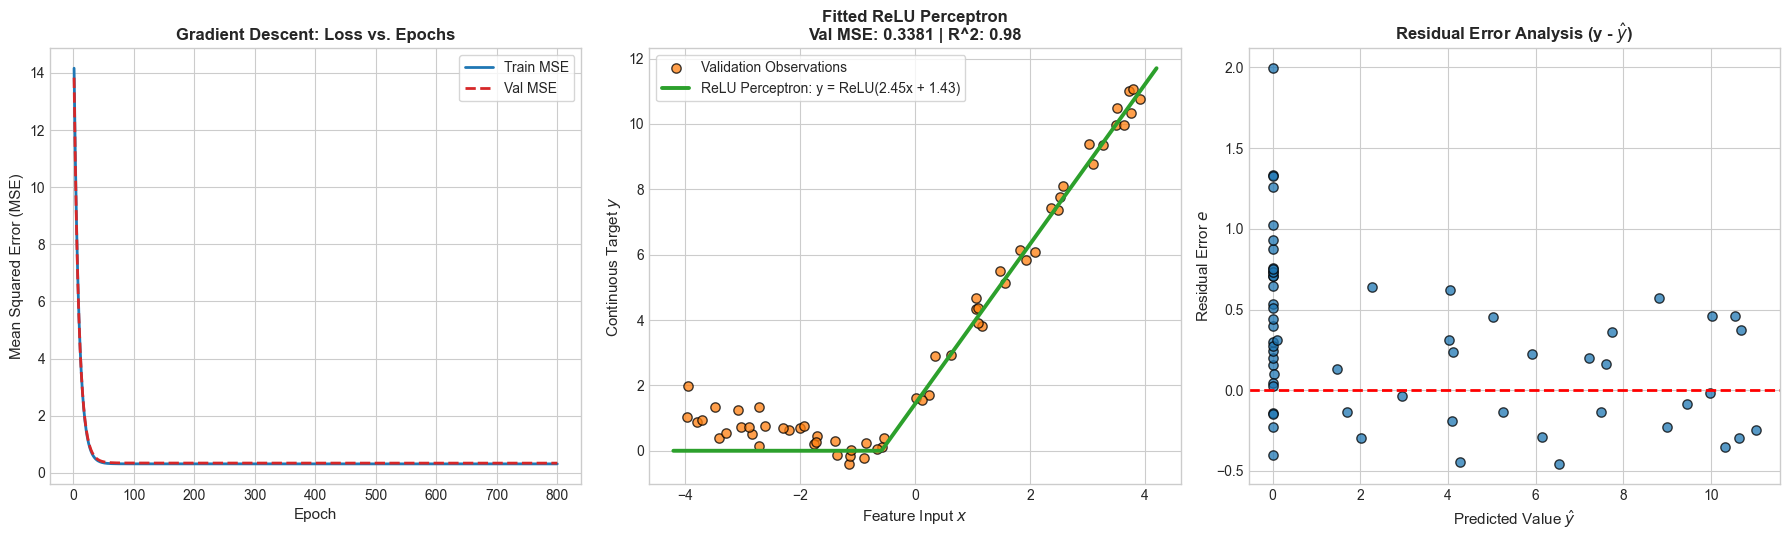

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

epochs_range = range(1, len(perceptron.history['train_loss']) + 1)
axes[0].plot(epochs_range, perceptron.history['train_loss'], label='Train MSE', color='#1f77b4', lw=2)
axes[0].plot(epochs_range, perceptron.history['val_loss'], label='Val MSE', color='#d62728', lw=2, linestyle='--')
axes[0].set_title('Gradient Descent: Loss vs. Epochs', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Mean Squared Error (MSE)', fontsize=11)
axes[0].legend(frameon=True, loc='upper right')

x_line = np.linspace(-4.2, 4.2, 300).reshape(-1, 1)
y_line = perceptron.predict(x_line)

axes[1].scatter(X_val, y_val, color='#ff7f0e', alpha=0.75, edgecolors='k', s=45, label='Validation Observations')
axes[1].plot(x_line, y_line, color='#2ca02c', lw=2.8, label=f'ReLU Perceptron: y = ReLU({perceptron.w:.2f}x + {perceptron.b:.2f})')
axes[1].set_title(f'Fitted ReLU Perceptron\nVal MSE: {perceptron.history["val_loss"][-1]:.4f} | R^2: {test_r2:.2f}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Feature Input $x$', fontsize=11)
axes[1].set_ylabel('Continuous Target $y$', fontsize=11)
axes[1].legend(frameon=True, loc='upper left')

val_preds = perceptron.predict(X_val)
residuals = y_val - val_preds

axes[2].scatter(val_preds, residuals, color='#1f77b4', alpha=0.75, edgecolors='k', s=45)
axes[2].axhline(0, color='red', linestyle='--', lw=2)
axes[2].set_title('Residual Error Analysis (y - $\hat{y}$)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Predicted Value $\hat{y}$', fontsize=11)
axes[2].set_ylabel('Residual Error $e$', fontsize=11)

plt.tight_layout()
plt.show()

### 8. Lecture Summary & Key Takeaways

| Concept | Mathematical Formula | Intuition |
| :--- | :--- | :--- |
| **Forward Pass** | $\hat{y} = \text{ReLU}(wx + b)$ | Maps input $x$ to pre-activation $z$, gated by $\max(0, z)$ |
| **Loss Model** | $\mathcal{L} = \frac{1}{2N} \sum (\hat{y}_i - y_i)^2$ | Quantifies average squared error penalty |
| **Combined Formula** | $\mathcal{L} = \frac{1}{2N} \sum \left(\text{ReLU}(wx_i + b) - y_i\right)^2$ | Direct substitution of $\hat{y}_i$ into the loss model |
| **ReLU Derivative** | $\frac{d}{dz}\text{ReLU}(z) = \mathbb{I}(z > 0)$ | Acts as an on/off gate for error propagation |
| **Weight Gradient** | $\frac{\partial \mathcal{L}}{\partial w} = \frac{1}{N} \sum (\hat{y}_i - y_i) \cdot \mathbb{I}(z_i > 0) \cdot x_i$ | Residual error scaled by input $x_i$, gated by active ReLU |
| **Bias Gradient** | $\frac{\partial \mathcal{L}}{\partial b} = \frac{1}{N} \sum (\hat{y}_i - y_i) \cdot \mathbb{I}(z_i > 0)$ | Residual error offset, gated by active ReLU |
| **Parameter Update** | $w \leftarrow w - \eta \frac{\partial \mathcal{L}}{\partial w}, \quad b \leftarrow b - \eta \frac{\partial \mathcal{L}}{\partial b}$ | Steps parameters downhill toward the loss minimum |

- **Three Takeaways to Emphasize in Lecture**:
  1. **ReLU Introduces Piecewise Non-Linearity**: Even with a single perceptron, ReLU enables the model to create a threshold hinge where it turns "on" or "off".
  2. **The Chain Rule Gating Mechanism**: The term $\mathbb{I}(z > 0)$ acts like an electrical switch. If the neuron's pre-activation is negative, the gradient is zero and no learning occurs from that sample.
  3. **Direct Equation Substitution Clarifies Derivation**: Writing $\mathcal{L} = \frac{1}{2N} \sum (\text{ReLU}(wx_i + b) - y_i)^2$ connects the loss, the activation, and the weights in one view.